# Staffing with Erlang C

Erlang C is a model for a phone queue, so it's run on calls only: the forecast per half-hour times phone's recent share of that half-hour.

Assumptions: an average handle time of 5 minutes, a target of 80% of calls answered within 20 seconds, and 30% shrinkage (breaks, training, meetings and absence).

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.data import model_series
from src.erlang import agents_needed, erlang_c, service_level, with_shrinkage

FIGURES = "../reports/figures/"
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

## Check against a worked example

In [2]:
erlang_c(10, 11), service_level(10, 13, aht=180, target_seconds=20)

(0.6821182046893325, 0.7955947884177831)

With 10 Erlangs of traffic and 11 agents, the textbook chance of waiting is 0.682, which the function matches. With 13 agents and a 3-minute handle time, 79.6% of calls are answered within 20 seconds.

## Calls per half-hour

In [3]:
daily = pd.read_parquet("../data/daily.parquet")
interval = pd.read_parquet("../data/interval.parquet")
y, usable = model_series(daily)

recent_days = daily.index[(daily["gap_hours"] == 0) & usable.to_numpy() & (daily.index >= "2026-09-19")]
recent = interval[interval.index.normalize().isin(recent_days)]
slot = [recent.index.day_of_week, recent.index.time]
phone_share = (recent.groupby(slot)["phone"].sum() / recent.groupby(slot)["total"].sum()).unstack()
len(recent_days), recent["phone"].sum() / recent["total"].sum()

(40, np.float64(0.2505916918305721))

Phone's share comes from the last 6 weeks (40 days without gaps), which are all after phone dropped again in mid-September. Overall it's 25.1%, but it's much higher at night than in the day.

In [4]:
forecast = pd.read_csv("../data/forecast_interval.csv", index_col="interval", parse_dates=True)["forecast"]
share = np.array([phone_share.loc[t.day_of_week, t.time()] for t in forecast.index])
calls = forecast * share
calls.sum(), calls.max(), calls.idxmax()

(np.float64(8434.883118930598),
 np.float64(34.10107224701515),
 Timestamp('2026-11-11 11:00:00'))

## Agents

In [5]:
agents = calls.apply(agents_needed)
scheduled = agents.apply(with_shrinkage)
agents.max(), scheduled.max(), (agents.groupby(agents.index.normalize()).sum() / 2).describe().round(1)

(np.int64(9),
 np.int64(13),
 count     14.0
 mean     103.6
 std       12.8
 min       81.5
 25%       93.4
 50%      104.5
 75%      113.5
 max      120.0
 Name: forecast, dtype: float64)

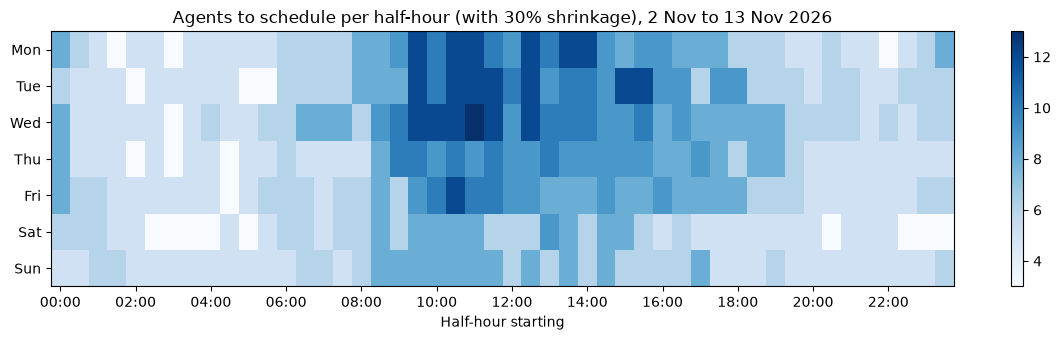

In [6]:
table = scheduled.groupby([scheduled.index.day_of_week, scheduled.index.time]).max().unstack()
table.index = DAYS

fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(table, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), DAYS)
ax.set_xticks(range(0, 48, 4), [str(t)[:5] for t in table.columns[::4]])
ax.set_xlabel("Half-hour starting")
ax.set_title("Agents to schedule per half-hour (with 30% shrinkage), 2 Nov to 13 Nov 2026")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES + "staffing_heatmap.png", dpi=150)
plt.show()

In [7]:
table

,00:00:00,00:30:00,01:00:00,01:30:00,02:00:00,02:30:00,03:00:00,03:30:00,04:00:00,04:30:00,...,19:00:00,19:30:00,20:00:00,20:30:00,21:00:00,21:30:00,22:00:00,22:30:00,23:00:00,23:30:00
Mon,8,6,5,3,5,5,3,5,5,5,...,6,5,5,6,5,5,3,5,6,8
Tue,6,5,5,5,3,5,5,5,5,5,...,6,6,5,6,6,5,5,6,6,6
Wed,8,5,5,5,5,5,3,5,6,5,...,8,6,6,6,6,5,6,5,6,6
Thu,8,5,5,5,3,5,3,5,5,3,...,8,6,5,5,5,5,5,5,5,5
Fri,8,6,6,5,5,5,5,5,5,3,...,6,6,5,5,5,5,5,5,6,6
Sat,6,6,6,5,5,3,3,3,3,5,...,5,5,5,3,5,5,5,3,3,3
Sun,5,5,6,6,5,5,5,5,5,5,...,6,5,5,5,5,5,5,5,5,6


In [8]:
table.to_csv("../data/staffing_by_slot.csv")

The table is the larger of the two forecast weeks for each weekday and half-hour, so the rota covers both. Weekdays from about 9:30 to 3:30 need 12 scheduled in most half-hours, with a peak of 13 (9 on the phones) at 11:00 on Wednesday. Nights never drop below 3 scheduled, because one agent alone can't answer 80% within 20 seconds once there's more than a trickle of calls, and phone is a bigger share of the small night volume.

## How much the handle time matters

In [9]:
pd.DataFrame({f"{aht // 60} min": {"agent-hours on the phones, 14 days": calls.apply(lambda c: agents_needed(c, aht=aht)).sum() / 2,
                                     "peak agents": calls.apply(lambda c: agents_needed(c, aht=aht)).max()}
              for aht in [240, 300, 360]}).T

,"agent-hours on the phones, 14 days",peak agents
4 min,1251.0,7.0
5 min,1451.0,9.0
6 min,1633.5,10.0


Each extra minute of handle time adds about 190 agent-hours over the two weeks, so getting the real handle time from the call center would matter more than any of the forecasting choices.